In [155]:
import warnings

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



warnings.filterwarnings('ignore')

In [156]:
df = pd.read_csv("cardekho.csv")

In [157]:
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.7000,796,46.3000,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.9000,1197,82.0000,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.0000,1197,80.0000,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.9200,998,67.1000,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.7700,1498,98.5900,5,570000


In [158]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')

In [159]:
df.drop("Unnamed: 0", axis=1, inplace=True)

In [160]:
df.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.7000,796,46.3000,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.9000,1197,82.0000,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.0000,1197,80.0000,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.9200,998,67.1000,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.7700,1498,98.5900,5,570000


In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   vehicle_age        15411 non-null  int64  
 4   km_driven          15411 non-null  int64  
 5   seller_type        15411 non-null  object 
 6   fuel_type          15411 non-null  object 
 7   transmission_type  15411 non-null  object 
 8   mileage            15411 non-null  float64
 9   engine             15411 non-null  int64  
 10  max_power          15411 non-null  float64
 11  seats              15411 non-null  int64  
 12  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.5+ MB


In [162]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.0000,15411.0000,15411.0000,15411.0000,15411.0000,15411.0000,15411.0000
mean,6.0363,55616.4806,19.7012,1486.0578,100.5883,5.3255,774971.1164
std,3.0133,51618.5484,4.1713,521.1067,42.9730,0.8076,894128.3633
min,0.0000,100.0000,4.0000,793.0000,38.4000,0.0000,40000.0000
25%,4.0000,30000.0000,17.0000,1197.0000,74.0000,5.0000,385000.0000
50%,6.0000,50000.0000,19.6700,1248.0000,88.5000,5.0000,556000.0000
75%,8.0000,70000.0000,22.7000,1582.0000,117.3000,5.0000,825000.0000
max,29.0000,3800000.0000,33.5400,6592.0000,626.0000,9.0000,39500000.0000


In [163]:
df[df.duplicated()]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
197,Honda City,Honda,City,8,70000,Individual,Petrol,Manual,16.8000,1497,116.3000,5,545000
360,Maruti Baleno,Maruti,Baleno,2,5000,Individual,Petrol,Automatic,21.4000,1197,83.1000,5,686000
1353,Maruti Swift Dzire,Maruti,Swift Dzire,4,50000,Individual,Diesel,Manual,28.4000,1248,74.0200,5,680000
1429,Maruti Wagon R,Maruti,Wagon R,13,100000,Individual,Petrol,Manual,18.9000,1061,67.0000,5,150000
1485,Hyundai i20,Hyundai,i20,3,50000,Individual,Petrol,Manual,18.6000,1197,81.8300,5,625000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15229,Maruti Swift,Maruti,Swift,8,80000,Individual,Diesel,Manual,22.9000,1248,74.0000,5,350000
15324,Maruti Wagon R,Maruti,Wagon R,6,50000,Individual,CNG,Manual,26.6000,998,58.1600,5,450000
15367,Tata Tiago,Tata,Tiago,4,30000,Individual,Petrol,Manual,23.8400,1199,84.0000,5,350000
15378,Hyundai Grand,Hyundai,Grand,6,30000,Individual,Petrol,Manual,18.9000,1197,82.0000,5,450000


In [164]:
df = df.drop_duplicates(keep='first', ignore_index=True)

df.loc[df["seats"] == 0,"seats"] = 5

In [165]:
pd.set_option('display.float_format', '{:.4f}'.format)

In [166]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15244.0000,15244.0000,15244.0000,15244.0000,15244.0000,15244.0000,15244.0000
mean,6.0411,55639.5823,19.6973,1486.1715,100.6077,5.3268,774701.4481
std,3.0162,51766.2993,4.1693,520.4194,42.9157,0.8065,894676.0819
min,0.0000,100.0000,4.0000,793.0000,38.4000,2.0000,40000.0000
25%,4.0000,30000.0000,17.0000,1197.0000,74.0000,5.0000,385000.0000
50%,6.0000,50000.0000,19.6700,1248.0000,88.5000,5.0000,559000.0000
75%,8.0000,70000.0000,22.7000,1582.0000,117.3000,5.0000,825000.0000
max,29.0000,3800000.0000,33.5400,6592.0000,626.0000,9.0000,39500000.0000


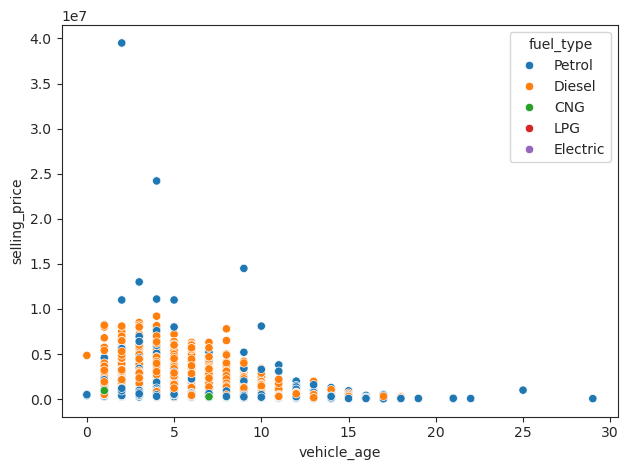

In [167]:
sns.scatterplot(x=df["vehicle_age"], y=df["selling_price"], hue=df["fuel_type"])
plt.tight_layout()
plt.show()

In [168]:
df = df[(df["selling_price"] < 10000000)]

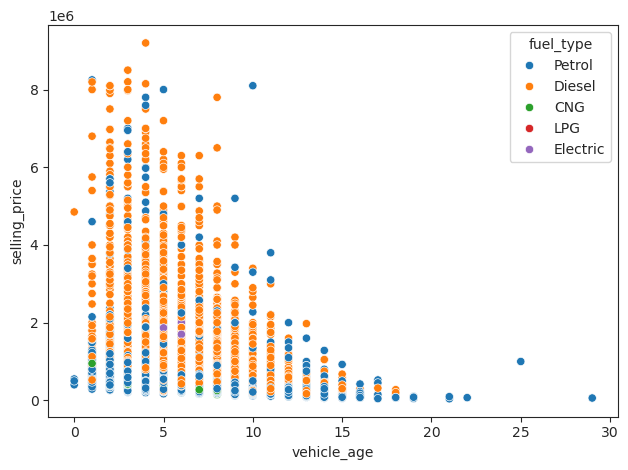

In [169]:
sns.scatterplot(x=df["vehicle_age"], y=df["selling_price"], hue=df["fuel_type"])
plt.tight_layout()
plt.show()

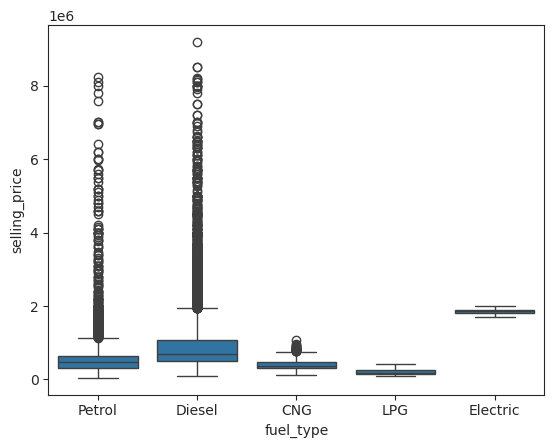

In [170]:
sns.boxplot(data=df, x="fuel_type", y="selling_price")
plt.show()

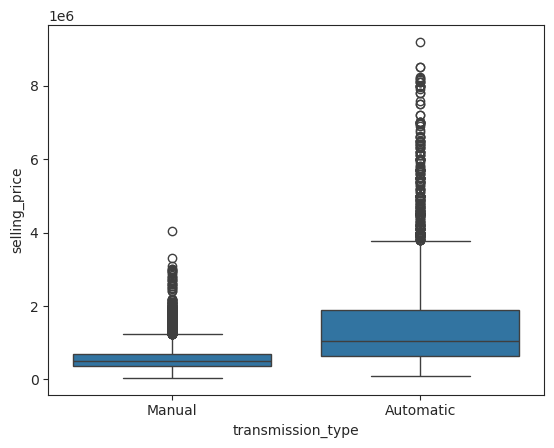

In [171]:
sns.boxplot(data=df, x="transmission_type", y="selling_price")
plt.show()

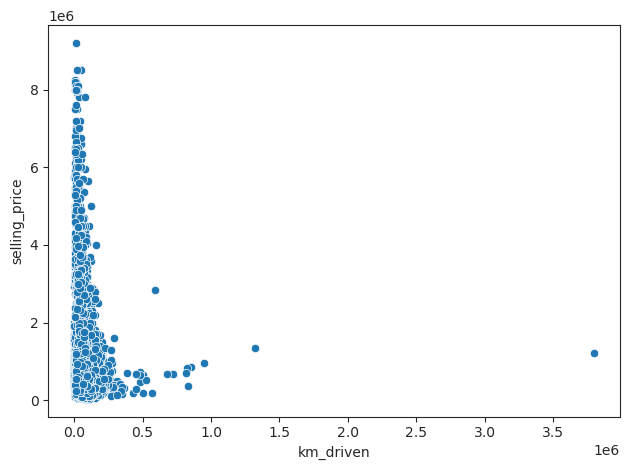

In [172]:
sns.scatterplot(x=df["km_driven"], y=df["selling_price"])
plt.tight_layout()
plt.show()

In [173]:
df = df[(df["km_driven"] < 1000000)]

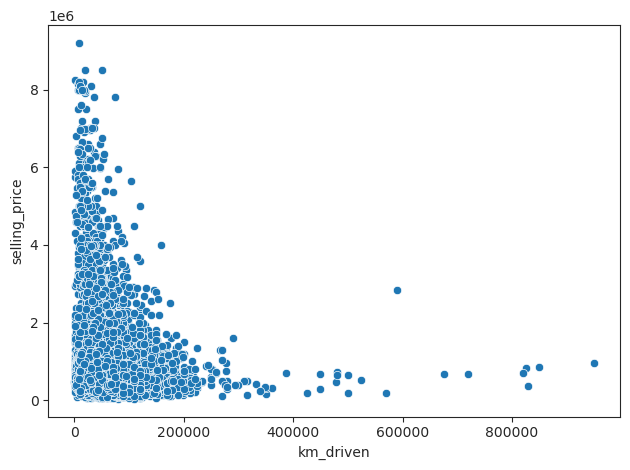

In [174]:
sns.scatterplot(x=df["km_driven"], y=df["selling_price"])
plt.tight_layout()
plt.show()

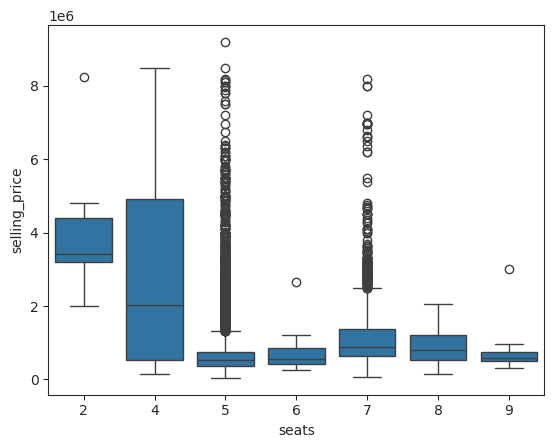

In [175]:
sns.boxplot(data=df, x="seats", y="selling_price")
plt.show()

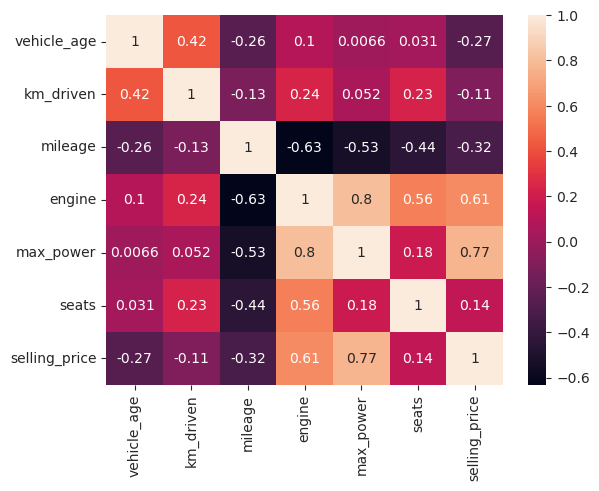

In [176]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [177]:
X = df.drop("selling_price", axis=1)
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [178]:
cat_cols = df.select_dtypes("object").columns.to_list()
cat_cols

['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']

In [179]:
nunique_values = df[cat_cols].nunique()
nunique_values

car_name             119
brand                 30
model                118
seller_type            3
fuel_type              5
transmission_type      2
dtype: int64

In [180]:
# seller_type, fuel_type, transmission_type -> one-hot encoding
# car_name, brand, model -> frequency encoding

In [181]:
onehot_columns = ["seller_type", "fuel_type", "transmission_type"]
frequency_columns = ["car_name", "brand", "model"]

for col in frequency_columns:
    freq = X_train[col].value_counts() / len(X_train)
    
    X_train[col + "_freq"] = X_train[col].map(freq) 
    
    X_test[col + "_freq"] = X_test[col].map(freq)

    mean_freq = freq.mean()
    X_test[col + "_freq"] = X_test[col + "_freq"].fillna(mean_freq)

In [182]:
X_train.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,car_name_freq,brand_freq,model_freq
14269,Maruti Swift,Maruti,Swift,7,70000,Individual,Diesel,Manual,25.2000,1248,74.0000,5,0.0502,0.3219,0.0502
1908,BMW 6,BMW,6,8,34000,Dealer,Diesel,Automatic,9.5200,2993,313.0000,4,0.0011,0.0290,0.0011
8033,Renault Duster,Renault,Duster,7,65000,Dealer,Diesel,Manual,20.4500,1461,83.8000,5,0.0138,0.0353,0.0138
9622,Maruti Swift Dzire,Maruti,Swift Dzire,6,65000,Dealer,Diesel,Manual,19.3000,1248,73.9000,5,0.0579,0.3219,0.0579
14792,Maruti Vitara,Maruti,Vitara,4,30000,Individual,Diesel,Manual,24.3000,1248,88.5000,5,0.0187,0.3219,0.0187


In [183]:
X_test.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,car_name_freq,brand_freq,model_freq
13653,Ford Ecosport,Ford,Ecosport,5,47935,Dealer,Petrol,Automatic,14.7000,1496,120.6900,5,0.0253,0.0512,0.0253
9896,Volkswagen Vento,Volkswagen,Vento,8,55000,Dealer,Diesel,Manual,20.3400,1498,103.2000,5,0.0161,0.0397,0.0161
6713,Skoda Superb,Skoda,Superb,10,80000,Individual,Petrol,Automatic,9.3000,2771,193.1000,5,0.0053,0.0220,0.0053
6828,Mahindra XUV500,Mahindra,XUV500,3,35000,Dealer,Diesel,Manual,15.1000,2179,152.8700,7,0.0216,0.0644,0.0216
1969,Maruti Ciaz,Maruti,Ciaz,5,94400,Individual,Diesel,Manual,28.0900,1248,88.5000,5,0.0225,0.3219,0.0225


In [184]:
X_train = X_train.drop(["car_name", "brand", "model"], axis=1)
X_test = X_test.drop(["car_name", "brand", "model"], axis=1)

In [185]:
transformer = ColumnTransformer(
                transformers=[
                    ("onehot", OneHotEncoder(drop='first', handle_unknown='ignore'), onehot_columns)

                ],remainder="passthrough"
                )

X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [186]:
encoded_cols = transformer.get_feature_names_out()
encoded_cols

array(['onehot__seller_type_Individual',
       'onehot__seller_type_Trustmark Dealer', 'onehot__fuel_type_Diesel',
       'onehot__fuel_type_Electric', 'onehot__fuel_type_LPG',
       'onehot__fuel_type_Petrol', 'onehot__transmission_type_Manual',
       'remainder__vehicle_age', 'remainder__km_driven',
       'remainder__mileage', 'remainder__engine', 'remainder__max_power',
       'remainder__seats', 'remainder__car_name_freq',
       'remainder__brand_freq', 'remainder__model_freq'], dtype=object)

In [187]:
X_train = pd.DataFrame(X_train, columns=encoded_cols)
X_test = pd.DataFrame(X_test, columns=encoded_cols)

In [188]:
X_train.head()

,onehot__seller_type_Individual,onehot__seller_type_Trustmark Dealer,onehot__fuel_type_Diesel,onehot__fuel_type_Electric,onehot__fuel_type_LPG,onehot__fuel_type_Petrol,onehot__transmission_type_Manual,remainder__vehicle_age,remainder__km_driven,remainder__mileage,remainder__engine,remainder__max_power,remainder__seats,remainder__car_name_freq,remainder__brand_freq,remainder__model_freq
0,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,7.0000,70000.0000,25.2000,1248.0000,74.0000,5.0000,0.0502,0.3219,0.0502
1,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,8.0000,34000.0000,9.5200,2993.0000,313.0000,4.0000,0.0011,0.0290,0.0011
2,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,7.0000,65000.0000,20.4500,1461.0000,83.8000,5.0000,0.0138,0.0353,0.0138
3,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,6.0000,65000.0000,19.3000,1248.0000,73.9000,5.0000,0.0579,0.3219,0.0579
4,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,4.0000,30000.0000,24.3000,1248.0000,88.5000,5.0000,0.0187,0.3219,0.0187


In [189]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11426 entries, 0 to 11425
Data columns (total 16 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   onehot__seller_type_Individual        11426 non-null  float64
 1   onehot__seller_type_Trustmark Dealer  11426 non-null  float64
 2   onehot__fuel_type_Diesel              11426 non-null  float64
 3   onehot__fuel_type_Electric            11426 non-null  float64
 4   onehot__fuel_type_LPG                 11426 non-null  float64
 5   onehot__fuel_type_Petrol              11426 non-null  float64
 6   onehot__transmission_type_Manual      11426 non-null  float64
 7   remainder__vehicle_age                11426 non-null  float64
 8   remainder__km_driven                  11426 non-null  float64
 9   remainder__mileage                    11426 non-null  float64
 10  remainder__engine                     11426 non-null  float64
 11  remainder__max_

In [211]:
models = {
    "tree" : DecisionTreeRegressor(),
    "adaboost_regressor" : AdaBoostRegressor()
}

for name, model in models.items():

    pipe = Pipeline([
        ("model", AdaBoostRegressor())
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    print(f"{name}_MSE: ", mean_squared_error(y_test, y_pred))
    print(f"{name}_MAE: ", mean_absolute_error(y_test, y_pred))
    print(f"{name}_R_Square: ", r2_score(y_test, y_pred))
    print("-"*50)

tree_MSE:  248789871553.52737
tree_MAE:  434217.5881553212
tree_R_Square:  0.6329548661382618
--------------------------------------------------
adaboost_regressor_MSE:  198927614737.73572
adaboost_regressor_MAE:  376796.7726124601
adaboost_regressor_R_Square:  0.7065177431690617
--------------------------------------------------


In [220]:
pipe1 = Pipeline([
        ("model", AdaBoostRegressor(DecisionTreeRegressor()))
    ])

params = {
    "model__estimator__max_depth" : [3, 4, 5],
    "model__n_estimators" : [50, 80, 100, 120],
    "model__learning_rate" : [0.001, 0.01, 0.1, 1.0, 2.0],
    "model__loss" : ['linear', 'square', 'exponantial']
}

rscv = RandomizedSearchCV(
    pipe1,
    param_distributions=params,
    cv=5,
    scoring="r2",
    verbose=1,
    n_jobs=-1
)

rscv.fit(X_train, y_train)
y_pred1 = rscv.predict(X_test)

print("\nBest Score: ", rscv.best_score_)
print("-"*100)
print("Best Parameters: ", rscv.best_params_)
print("-"*100)
print(f"{name}_MSE: ", mean_squared_error(y_test, y_pred1))
print(f"{name}_MAE: ", mean_absolute_error(y_test, y_pred1))
print(f"{name}_R_Square: ", r2_score(y_test, y_pred1))

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best Score:  0.8997460874076442
----------------------------------------------------------------------------------------------------
Best Parameters:  {'model__n_estimators': 120, 'model__loss': 'linear', 'model__learning_rate': 0.1, 'model__estimator__max_depth': 5}
----------------------------------------------------------------------------------------------------
adaboost_regressor_MSE:  66765269516.17681
adaboost_regressor_MAE:  144649.51413472928
adaboost_regressor_R_Square:  0.9014997389811037
